# Tarea 1: Descomposición de Canales y Espacios de Color
**Materia:** Inteligencia Artificial  
**Objetivo:**
1. Tomar una imagen a color y separar sus canales (R, G, B) de forma manual (aproximación matemática/matricial tradicional, manipulando arreglos sin usar funciones de librerías de visión).

Y como elementos adicionales decidí agregar:

2. Separar los canales utilizando OpenCV (`cv2.split`).
3. Convertir y visualizar la imagen en distintos espacios de colores (HSV, LAB, YCrCb, Escala de Grises).


### 1. Importar librerías necesarias


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Ruta de una imagen de prueba del dataset
ruta_imagen = 'imagenes/ejemplo.jpg'

# Cargamos la imagen original en formato RGB
# Usamos PIL solo para leer el archivo a un arreglo de números (matriz H x W x 3)
img_pil = Image.open(ruta_imagen)
img_rgb = np.array(img_pil)

print(f"Dimensiones de la imagen: {img_rgb.shape} (Alto, Ancho, Canales)")


Dimensiones de la imagen: (200, 300, 3) (Alto, Ancho, Canales)


### 2. Visualizar imagen original


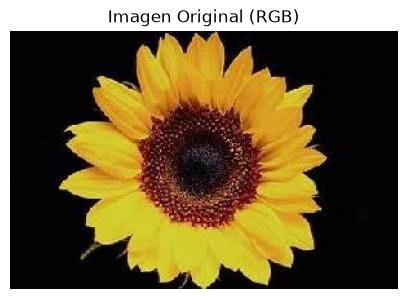

In [2]:
plt.figure(figsize=(5, 5))
plt.imshow(img_rgb)
plt.title("Imagen Original (RGB)")
plt.axis('off')
plt.show()


### 3. Separación de canales de forma tradicional (Matemática / Matricial)

Una imagen a color digital es una matriz de dimensiones $(Alto, Ancho, 3)$:
- Canal 0 = Rojo ($R$)
- Canal 1 = Verde ($G$)
- Canal 2 = Azul ($B$)

Podemos extraer cada canal matemáticamente seleccionando la rebanada correspondiente del arreglo:
$$R = I[:, :, 0], \quad G = I[:, :, 1], \quad B = I[:, :, 2]$$

Para visualizarlos en color real, creamos una matriz con ceros y colocamos únicamente el canal correspondiente.


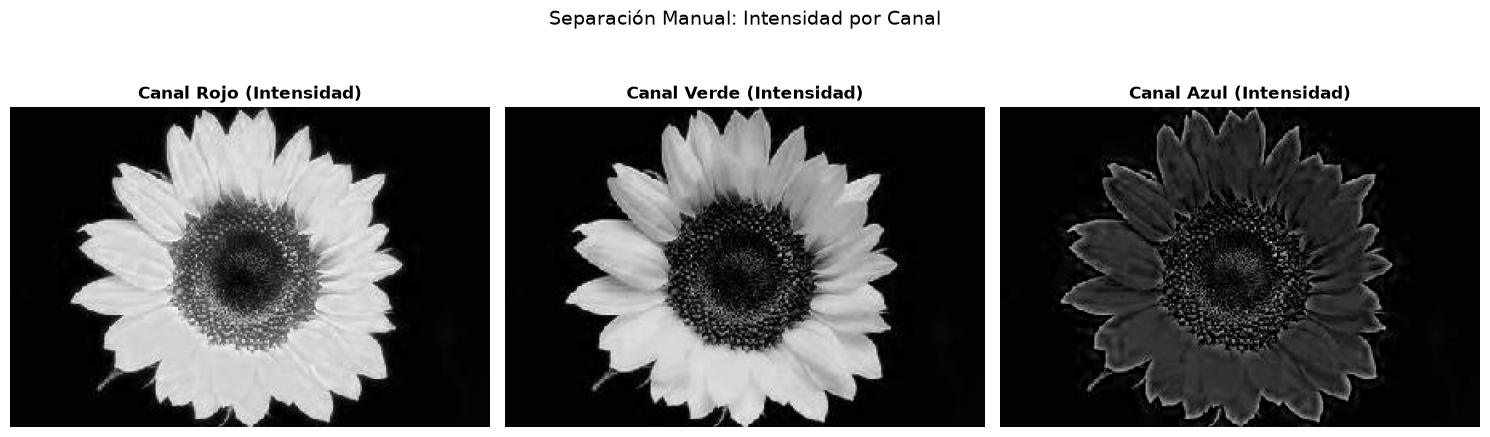

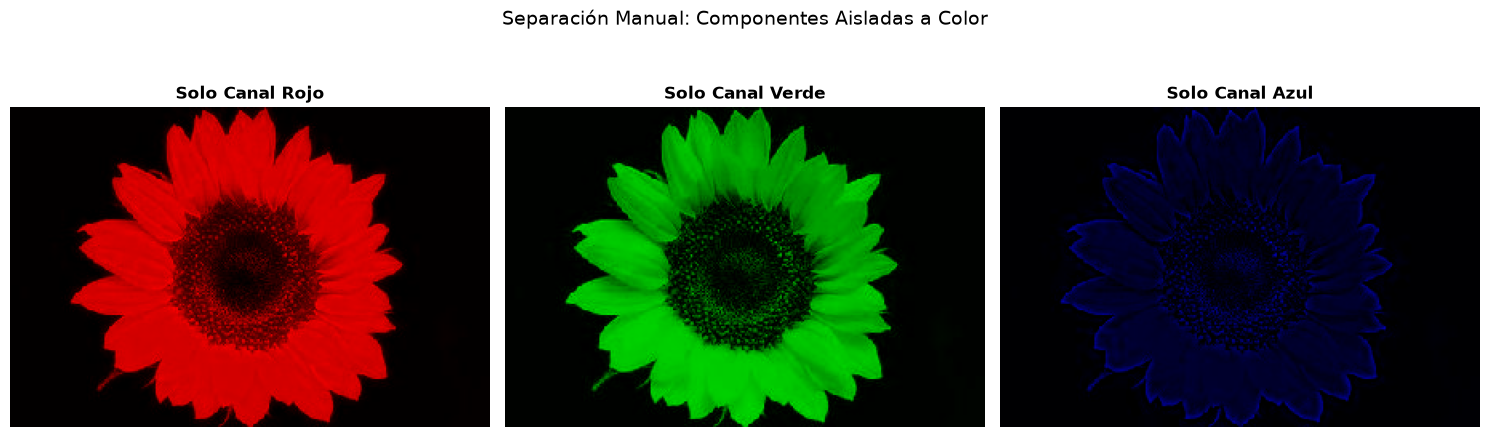

In [3]:
# 1. Extracción directa del valor numérico de cada canal (matriz 2D)
canal_r = img_rgb[:, :, 0]
canal_g = img_rgb[:, :, 1]
canal_b = img_rgb[:, :, 2]

# 2. Reconstrucción en color aislando cada canal (dejando los otros dos en 0)
solo_rojo = np.zeros_like(img_rgb)
solo_rojo[:, :, 0] = canal_r

solo_verde = np.zeros_like(img_rgb)
solo_verde[:, :, 1] = canal_g

solo_azul = np.zeros_like(img_rgb)
solo_azul[:, :, 2] = canal_b

# Graficamos en escala de grises (intensidad pura del canal)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(canal_r, cmap='gray')
axes[0].set_title("Canal Rojo (Intensidad)", fontweight='bold')
axes[0].axis('off')

axes[1].imshow(canal_g, cmap='gray')
axes[1].set_title("Canal Verde (Intensidad)", fontweight='bold')
axes[1].axis('off')

axes[2].imshow(canal_b, cmap='gray')
axes[2].set_title("Canal Azul (Intensidad)", fontweight='bold')
axes[2].axis('off')

plt.suptitle("Separación Manual: Intensidad por Canal", fontsize=14)
plt.tight_layout()
plt.show()

# Graficamos con su componente de color visual
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(solo_rojo)
axes[0].set_title("Solo Canal Rojo", fontweight='bold')
axes[0].axis('off')

axes[1].imshow(solo_verde)
axes[1].set_title("Solo Canal Verde", fontweight='bold')
axes[1].axis('off')

axes[2].imshow(solo_azul)
axes[2].set_title("Solo Canal Azul", fontweight='bold')
axes[2].axis('off')

plt.suptitle("Separación Manual: Componentes Aisladas a Color", fontsize=14)
plt.tight_layout()
plt.show()


### 4. Separación de canales usando OpenCV (`cv2`)
OpenCV lee las imágenes por defecto en formato **BGR** en vez de **RGB**, por lo que convertimos a RGB o desempaquetamos considerando el orden de OpenCV con `cv2.split()`.


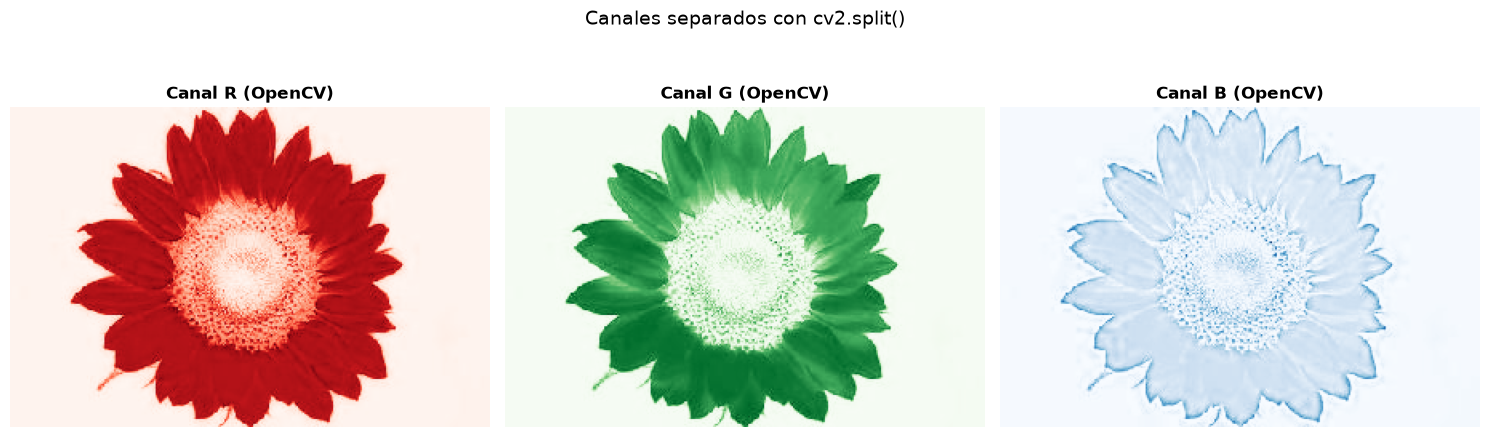

In [4]:
# Leemos la imagen directamente con OpenCV
img_bgr = cv2.imread(ruta_imagen)

# Usamos la función nativa cv2.split
b_cv, g_cv, r_cv = cv2.split(img_bgr)

# Visualizamos los 3 canales obtenidos con cv2
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(r_cv, cmap='Reds')
axes[0].set_title("Canal R (OpenCV)", fontweight='bold')
axes[0].axis('off')

axes[1].imshow(g_cv, cmap='Greens')
axes[1].set_title("Canal G (OpenCV)", fontweight='bold')
axes[1].axis('off')

axes[2].imshow(b_cv, cmap='Blues')
axes[2].set_title("Canal B (OpenCV)", fontweight='bold')
axes[2].axis('off')

plt.suptitle("Canales separados con cv2.split()", fontsize=14)
plt.tight_layout()
plt.show()


### 5. Representación en distintos espacios de colores
Convertimos la imagen a otros modelos de color comúnmente utilizados en visión artificial:
1. **Escala de Grises (GRAY):** Representa solo la luminancia o brillo ($Y = 0.299R + 0.587G + 0.114B$).
2. **HSV (Hue, Saturation, Value):** Matiz (tono del color), Saturación (pureza) y Valor (brillo). Muy útil para segmentar por color.
3. **LAB (Luminance, A, B):** Diseñado para asemejarse a la visión humana. Separa el brillo ($L$) de los componentes de color ($A$: verde-rojo, $B$: azul-amarillo).
4. **YCrCb:** Usado en transmisiones de video y compresión JPEG. $Y$ es la luminancia, $Cr$ y $Cb$ son las diferencias de color.


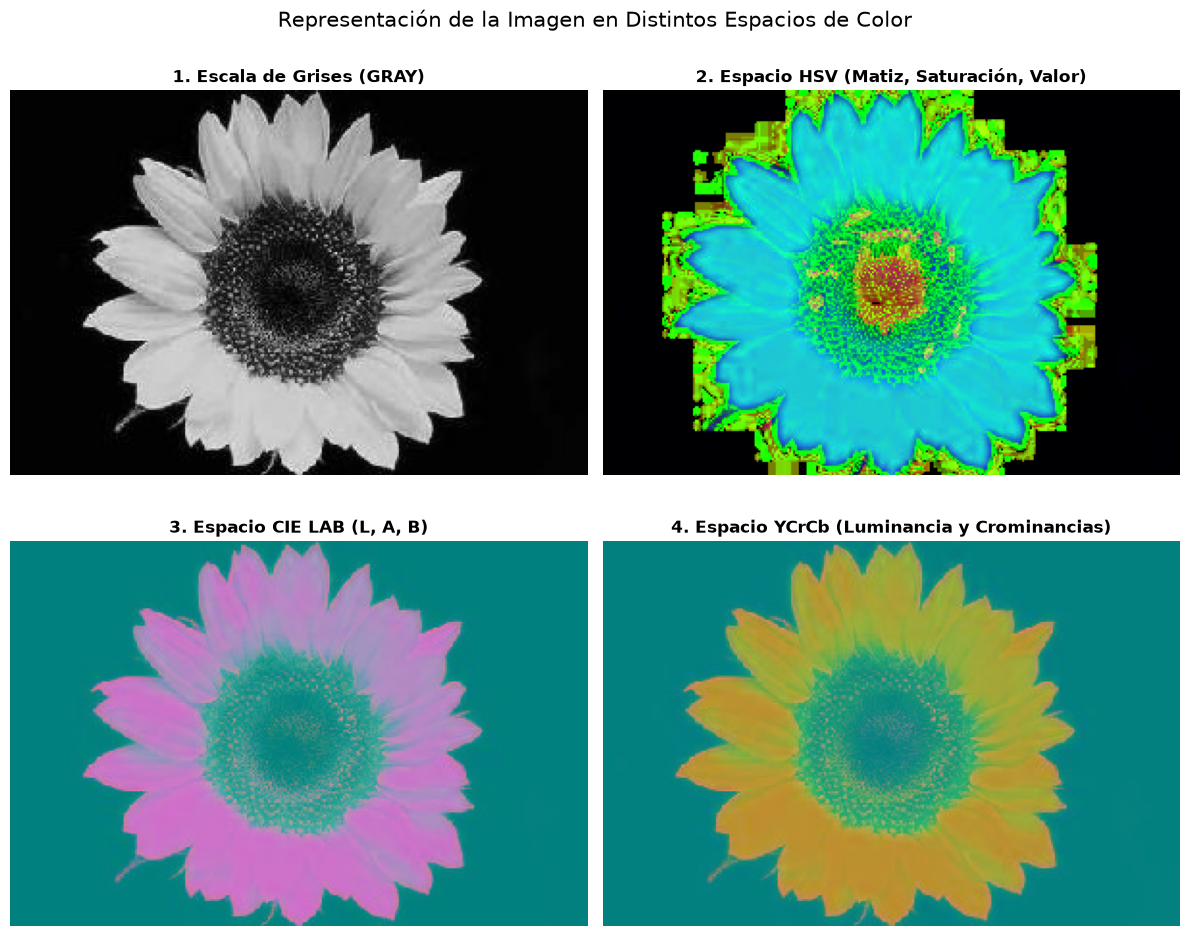

In [5]:
# Conversiones de espacios de color con OpenCV
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
img_ycrcb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2YCrCb)

# Mostramos cada espacio de color
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(img_gray, cmap='gray')
axes[0, 0].set_title("1. Escala de Grises (GRAY)", fontweight='bold')
axes[0, 0].axis('off')

axes[0, 1].imshow(img_hsv)
axes[0, 1].set_title("2. Espacio HSV (Matiz, Saturación, Valor)", fontweight='bold')
axes[0, 1].axis('off')

axes[1, 0].imshow(img_lab)
axes[1, 0].set_title("3. Espacio CIE LAB (L, A, B)", fontweight='bold')
axes[1, 0].axis('off')

axes[1, 1].imshow(img_ycrcb)
axes[1, 1].set_title("4. Espacio YCrCb (Luminancia y Crominancias)", fontweight='bold')
axes[1, 1].axis('off')

plt.suptitle("Representación de la Imagen en Distintos Espacios de Color", fontsize=15, y=0.98)
plt.tight_layout()
plt.show()


### 6. Desglose de canales en HSV y LAB
Para entender cómo funciona cada espacio, podemos descomponer cada uno de sus canales individuales:


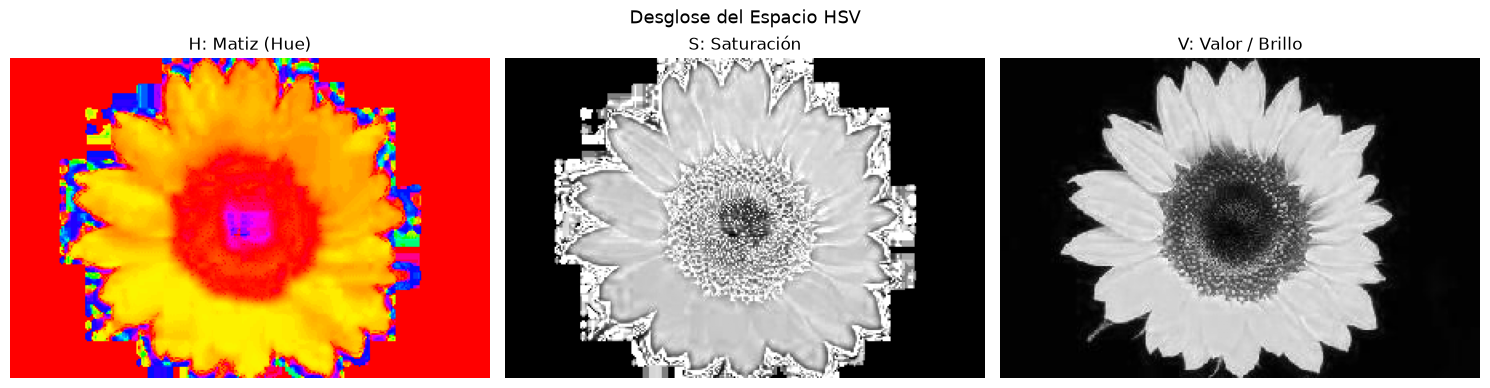

In [6]:
# Desglose de canales en HSV
h, s, v = cv2.split(img_hsv)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(h, cmap='hsv')
axes[0].set_title("H: Matiz (Hue)")
axes[0].axis('off')

axes[1].imshow(s, cmap='gray')
axes[1].set_title("S: Saturación")
axes[1].axis('off')

axes[2].imshow(v, cmap='gray')
axes[2].set_title("V: Valor / Brillo")
axes[2].axis('off')

plt.suptitle("Desglose del Espacio HSV", fontsize=13)
plt.tight_layout()
plt.show()


### Conclusiones breves:
- **Aproximación matemática:** Una imagen digital es simplemente una matriz tridimensional. Separar canales consiste en indexar la matriz en su tercera dimensión (`[:, :, c]`).
- **OpenCV (`cv2.split`):** Facilita este proceso directamente en una sola línea de código, teniendo siempre presente el orden BGR.
- **Espacios de color:** Cada espacio separa la información de forma distinta. Mientras que **RGB** mezcla el color y la iluminación en cada canal, espacios como **HSV**, **LAB** y **YCrCb** separan el brillo/luminancia del tono del color, facilitando tareas como detección y segmentación de objetos.
